<a href="https://colab.research.google.com/github/jeris01/gaming-behaviour-academic-performance/blob/main/Gaming_Behavior_Academic_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gaming Behavior and Academic Performance Analysis
### Beginner-friendly B.Tech AI & Data Science project

**Goal:** Explore how gaming habits relate to students' academic performance using Python, Pandas, Matplotlib, and Seaborn.

**Important data note:** This notebook creates a **synthetic (computer-generated) example dataset** so you can learn the workflow immediately. It is not real student data and must not be presented as a real survey. Replace it with an ethically collected, anonymized dataset if your assignment requires real-world evidence.

### What you will learn
- Load and inspect tabular data
- Check missing values and duplicates
- Summarize gaming, study, sleep, attendance, and exam scores
- Create charts and calculate correlations
- Explain findings carefully without claiming that correlation proves causation

### Project questions
1. How are gaming hours and exam scores associated?
2. How are study hours and exam scores associated?
3. How do sleep and attendance relate to exam scores?
4. Which numerical variables have the strongest correlations with exam score?

## 1. Import the libraries

Pandas handles tables, NumPy helps generate example data, Matplotlib and Seaborn create charts.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make example results reproducible each time you run the notebook
np.random.seed(42)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Create a sample dataset

We will simulate 500 fictional students. The variables are designed to have plausible ranges. The data-generation formula intentionally introduces relationships so that you can practise analysis; this means the results are **demonstration results, not evidence about real students**.

If you later collect real data, use informed consent, avoid names/student IDs, and follow your institution's rules.

In [14]:
n = 500

# Simulated student habits
gaming_hours = np.clip(np.random.normal(2.5, 1.5, n), 0, 8)
study_hours = np.clip(np.random.normal(2.8, 1.2, n), 0, 7)
sleep_hours = np.clip(np.random.normal(7.0, 1.0, n), 4, 10)
attendance_pct = np.clip(np.random.normal(85, 10, n), 45, 100)

# A demonstration score formula: study and attendance contribute positively;
# gaming hours have a small negative association in this synthetic example.
# Random noise represents other unmeasured influences.
noise = np.random.normal(0, 9, n)
exam_score = (
    42
    + 5.0 * study_hours
    + 0.18 * (attendance_pct - 75)
    + 1.5 * (sleep_hours - 7)
    - 1.4 * gaming_hours
    + noise
)
exam_score = np.clip(exam_score, 0, 100)

df = pd.DataFrame({
    "student_id": [f"S{i:03d}" for i in range(1, n + 1)],
    "gaming_hours": np.round(gaming_hours, 1),
    "study_hours": np.round(study_hours, 1),
    "sleep_hours": np.round(sleep_hours, 1),
    "attendance_pct": np.round(attendance_pct, 1),
    "exam_score": np.round(exam_score, 1)
})

df.head()

,student_id,gaming_hours,study_hours,sleep_hours,attendance_pct,exam_score
0,S001,3.2,3.9,8.4,92.8,56.2
1,S002,2.3,5.1,7.9,79.5,65.1
2,S003,3.5,1.1,7.1,76.8,36.0
3,S004,4.8,3.5,6.4,85.0,50.7
4,S005,2.1,2.0,7.7,83.3,34.6


## 3. Inspect the data

- `head()` shows the first five rows.
- `shape` gives the number of rows and columns.
- `info()` shows column types and whether values are missing.
- `describe()` gives summary statistics.

In [15]:
print("Dataset shape (rows, columns):", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn information:")
df.info()

print("\nSummary statistics:")
display(df.describe().round(2))

Dataset shape (rows, columns): (500, 6)

First 5 rows:


,student_id,gaming_hours,study_hours,sleep_hours,attendance_pct,exam_score
0,S001,3.2,3.9,8.4,92.8,56.2
1,S002,2.3,5.1,7.9,79.5,65.1
2,S003,3.5,1.1,7.1,76.8,36.0
3,S004,4.8,3.5,6.4,85.0,50.7
4,S005,2.1,2.0,7.7,83.3,34.6



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   student_id      500 non-null    object 
 1   gaming_hours    500 non-null    float64
 2   study_hours     500 non-null    float64
 3   sleep_hours     500 non-null    float64
 4   attendance_pct  500 non-null    float64
 5   exam_score      500 non-null    float64
dtypes: float64(5), object(1)
memory usage: 23.6+ KB

Summary statistics:


,gaming_hours,study_hours,sleep_hours,attendance_pct,exam_score
count,500.00,500.00,500.00,500.00,500.00
mean,2.53,2.84,7.11,85.05,54.53
std,1.43,1.17,1.01,9.28,10.91
min,0.00,0.00,4.10,55.60,18.50
25%,1.48,2.10,6.40,78.90,47.20
50%,2.50,2.80,7.10,84.95,55.05
75%,3.50,3.60,7.80,92.02,62.40
max,8.00,6.00,9.60,100.00,85.20


## 4. Check data quality

We check missing values, duplicate rows, and whether values fall within sensible ranges. Since this is generated data, it should not contain missing values or duplicate rows.

In [16]:
print("Missing values in each column:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Values outside expected ranges:")
print("Gaming hours outside 0–24:", ((df["gaming_hours"] < 0) | (df["gaming_hours"] > 24)).sum())
print("Study hours outside 0–24:", ((df["study_hours"] < 0) | (df["study_hours"] > 24)).sum())
print("Attendance outside 0–100:", ((df["attendance_pct"] < 0) | (df["attendance_pct"] > 100)).sum())
print("Exam scores outside 0–100:", ((df["exam_score"] < 0) | (df["exam_score"] > 100)).sum())

Missing values in each column:


,0
student_id,0
gaming_hours,0
study_hours,0
sleep_hours,0
attendance_pct,0
exam_score,0


Duplicate rows: 0
Values outside expected ranges:
Gaming hours outside 0–24: 0
Study hours outside 0–24: 0
Attendance outside 0–100: 0
Exam scores outside 0–100: 0


## 5. Create useful categories

These categories make group comparisons easier. They are simple project choices, not official academic standards.

In [17]:
df["gaming_group"] = pd.cut(
    df["gaming_hours"],
    bins=[-0.01, 1, 3, 5, 8],
    labels=["Low (≤1 h)", "Moderate (1–3 h)", "High (3–5 h)", "Very high (>5 h)"]
)

df["study_group"] = pd.cut(
    df["study_hours"],
    bins=[-0.01, 1, 3, 5, 7],
    labels=["Low (≤1 h)", "Moderate (1–3 h)", "High (3–5 h)", "Very high (>5 h)"]
)

display(df[["gaming_hours", "gaming_group", "study_hours", "study_group", "exam_score"]].head())

,gaming_hours,gaming_group,study_hours,study_group,exam_score
0,3.2,High (3–5 h),3.9,High (3–5 h),56.2
1,2.3,Moderate (1–3 h),5.1,Very high (>5 h),65.1
2,3.5,High (3–5 h),1.1,Moderate (1–3 h),36.0
3,4.8,High (3–5 h),3.5,High (3–5 h),50.7
4,2.1,Moderate (1–3 h),2.0,Moderate (1–3 h),34.6


## 6. Explore the distributions

Histograms help show how values are spread out. Each chart shows one variable.

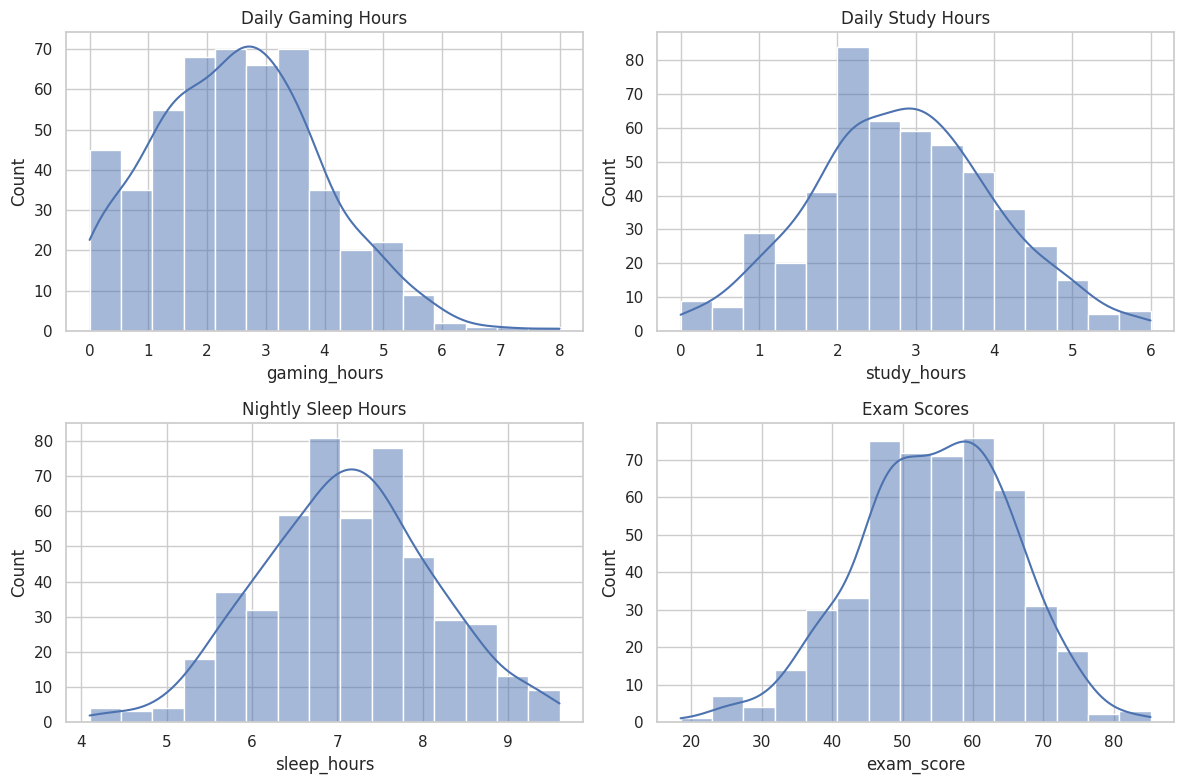

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["gaming_hours"], bins=15, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Daily Gaming Hours")

sns.histplot(df["study_hours"], bins=15, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Daily Study Hours")

sns.histplot(df["sleep_hours"], bins=15, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Nightly Sleep Hours")

sns.histplot(df["exam_score"], bins=15, kde=True, ax=axes[1, 1])
axes[1, 1].set_title("Exam Scores")

plt.tight_layout()
plt.show()

## 7. Gaming hours versus exam score

A scatter plot shows individual observations. The trend line is a simple visual summary, not proof that gaming causes a change in marks.

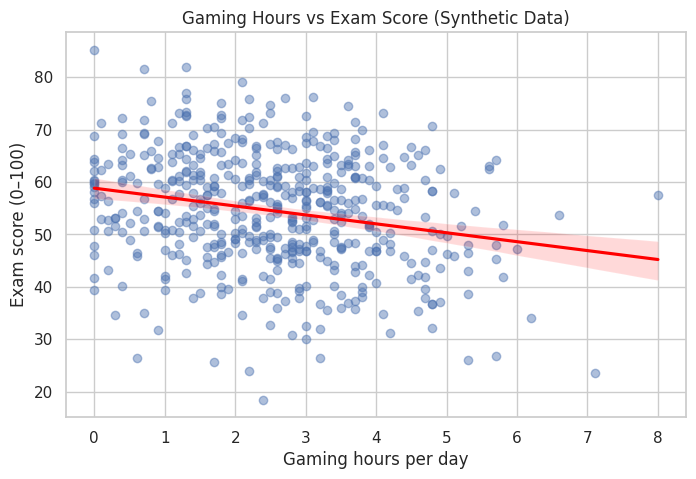

Pearson correlation between gaming hours and exam score: -0.222


In [19]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="gaming_hours", y="exam_score",
            scatter_kws={"alpha": 0.45}, line_kws={"color": "red"})
plt.title("Gaming Hours vs Exam Score (Synthetic Data)")
plt.xlabel("Gaming hours per day")
plt.ylabel("Exam score (0–100)")
plt.show()

gaming_corr = df["gaming_hours"].corr(df["exam_score"])
print(f"Pearson correlation between gaming hours and exam score: {gaming_corr:.3f}")

## 8. Study time versus exam score

Repeat the analysis for study time. The pattern may look different from the gaming-hours chart.

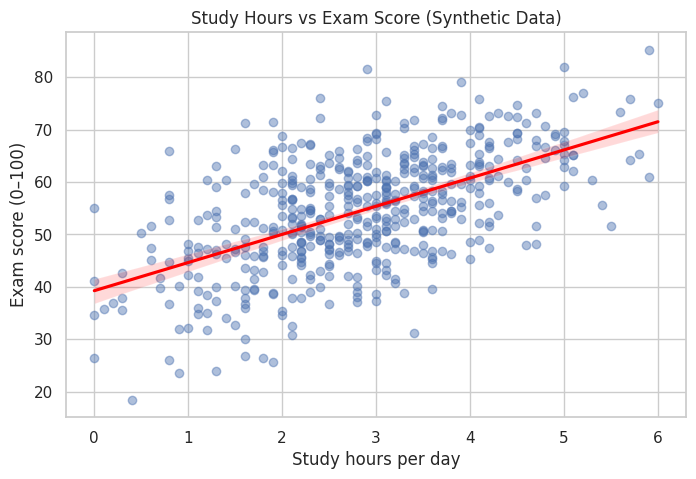

Pearson correlation between study hours and exam score: 0.574


In [20]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="study_hours", y="exam_score",
            scatter_kws={"alpha": 0.45}, line_kws={"color": "red"})
plt.title("Study Hours vs Exam Score (Synthetic Data)")
plt.xlabel("Study hours per day")
plt.ylabel("Exam score (0–100)")
plt.show()

study_corr = df["study_hours"].corr(df["exam_score"])
print(f"Pearson correlation between study hours and exam score: {study_corr:.3f}")

## 9. Compare average scores across gaming groups

A group average can be easy to explain in a presentation. Always show the number of students in each group too, because group sizes may differ.

,student_count,average_exam_score,average_study_hours
gaming_group,,,
Low (≤1 h),80,56.31,2.87
Moderate (1–3 h),251,55.40,2.88
High (3–5 h),147,53.21,2.75
Very high (>5 h),22,46.89,2.82


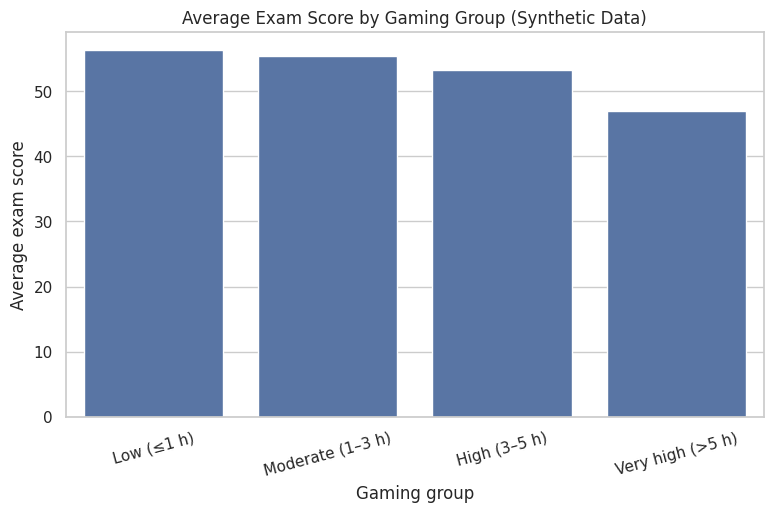

In [21]:
group_summary = (
    df.groupby("gaming_group", observed=False)
      .agg(
          student_count=("student_id", "count"),
          average_exam_score=("exam_score", "mean"),
          average_study_hours=("study_hours", "mean")
      )
      .round(2)
)

display(group_summary)

plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="gaming_group", y="exam_score", errorbar=None)
plt.title("Average Exam Score by Gaming Group (Synthetic Data)")
plt.xlabel("Gaming group")
plt.ylabel("Average exam score")
plt.xticks(rotation=15)
plt.show()

## 10. Correlation heatmap

Pearson correlation ranges from -1 to +1:
- Near +1: stronger positive linear association
- Near -1: stronger negative linear association
- Near 0: little or no linear association

A correlation does not show causation and may miss non-linear patterns.

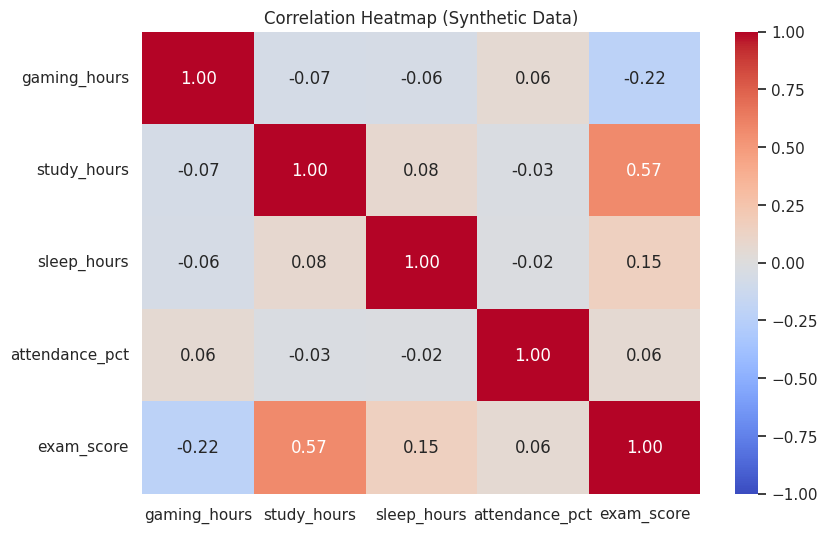

,gaming_hours,study_hours,sleep_hours,attendance_pct,exam_score
gaming_hours,1.000,-0.068,-0.057,0.061,-0.222
study_hours,-0.068,1.000,0.077,-0.026,0.574
sleep_hours,-0.057,0.077,1.000,-0.019,0.153
attendance_pct,0.061,-0.026,-0.019,1.000,0.058
exam_score,-0.222,0.574,0.153,0.058,1.000


In [22]:
numeric_cols = [
    "gaming_hours", "study_hours", "sleep_hours",
    "attendance_pct", "exam_score"
]
correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Heatmap (Synthetic Data)")
plt.show()

display(correlation_matrix.round(3))

## 11. Optional: use your own CSV dataset

If your teacher gives you a real dataset, upload it in Colab using the file panel or the code below. Your CSV should contain columns corresponding to the fields used in this notebook.

**Expected column names:** `gaming_hours`, `study_hours`, `sleep_hours`, `attendance_pct`, and `exam_score`.

Uncomment and run this cell after uploading your file. Change the filename if needed.

In [23]:
# from google.colab import files
# uploaded = files.upload()
# real_df = pd.read_csv("your_dataset.csv")
# print(real_df.head())
# print(real_df.isnull().sum())
#
# # Check that the required columns are present
# required_columns = [
#     "gaming_hours", "study_hours", "sleep_hours",
#     "attendance_pct", "exam_score"
# ]
# missing_columns = [col for col in required_columns if col not in real_df.columns]
# if missing_columns:
#     print("Please rename or map these missing columns:", missing_columns)
# else:
#     display(real_df[required_columns].describe().round(2))

## 12. Export the sample data and charts

This saves the synthetic dataset as a CSV file. Label it as synthetic if you submit or share it.

In [24]:
df.to_csv("gaming_academic_synthetic_data.csv", index=False)
print("Saved: gaming_academic_synthetic_data.csv")

# In Google Colab, uncomment the next two lines to download the file:
# from google.colab import files
# files.download("gaming_academic_synthetic_data.csv")

Saved: gaming_academic_synthetic_data.csv


## 13. How to write your conclusion

After running all cells, write your conclusion using the actual values printed by the notebook. You can use this structure:

1. **Dataset:** This notebook used 500 synthetic student records for practice.
2. **Gaming and marks:** Report the calculated correlation and describe whether the association is positive, negative, or weak.
3. **Study and marks:** Report the calculated correlation and describe the pattern.
4. **Other factors:** Discuss sleep and attendance correlations.
5. **Limitations:** The data is synthetic, relationships were built into the data-generation formula, and results cannot be generalized to real students.
6. **Future work:** Collect a larger, anonymized, consent-based dataset; document how variables were measured; and test whether results remain similar after accounting for other factors.

### Limitations to mention in your report
- Synthetic data is only for learning and testing code.
- Correlation does not establish cause and effect.
- Exam scores can depend on many factors not included here, such as prior knowledge, course difficulty, stress, health, and teaching methods.
- Self-reported gaming or study hours may be inaccurate in a real survey.
- Do not use this analysis to label or judge individual students.

## 14. Project checklist

- [ ] Run every notebook cell from top to bottom.
- [ ] Check that charts have titles and labelled axes.
- [ ] Record the correlations and group averages from your run.
- [ ] Write a conclusion that matches the output.
- [ ] If using real data, remove identifying details and get the required permission.
- [ ] Clearly state whether the dataset is synthetic or real.
- [ ] Add this notebook and your README to a GitHub repository.